****    ASSIGNEMT 2  JESCA NAMPEWO B28749  ****

In [ ]:
Project 1. Wholesale customers

In [ ]:
#Data exploration

#Loading the dataset
import pandas as pd
wholesale_df=pd.read_csv("wholesale-customers.csv")
wholesale_df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [ ]:
wholesale_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicatessen      440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


The data was successfully loaded using pandas and it consists of 8 columns and 440 entries which are all quantitative columns.

In [ ]:
#Checking for missing values
print("\nMissing values:")
print(wholesale_df.isnull().sum())

#Checking duplicated records
print("\nDuplicate records:", wholesale_df.duplicated().sum())

#Generating descriptive statistics
wholesale_df.describe()


Missing values:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicatessen        0
dtype: int64

Duplicate records: 0


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


The data indicates that there are no missing values as well as no duplicated rows.after looking at the descriptive statistics for the dataframe,its clear that the columns for channel and Region were categorical variables that were encoded.The descriptive statistics indicates that avaerage spending is higher on fresh products as compared to the other products and avaerage spending is lowest with Delicatessen products

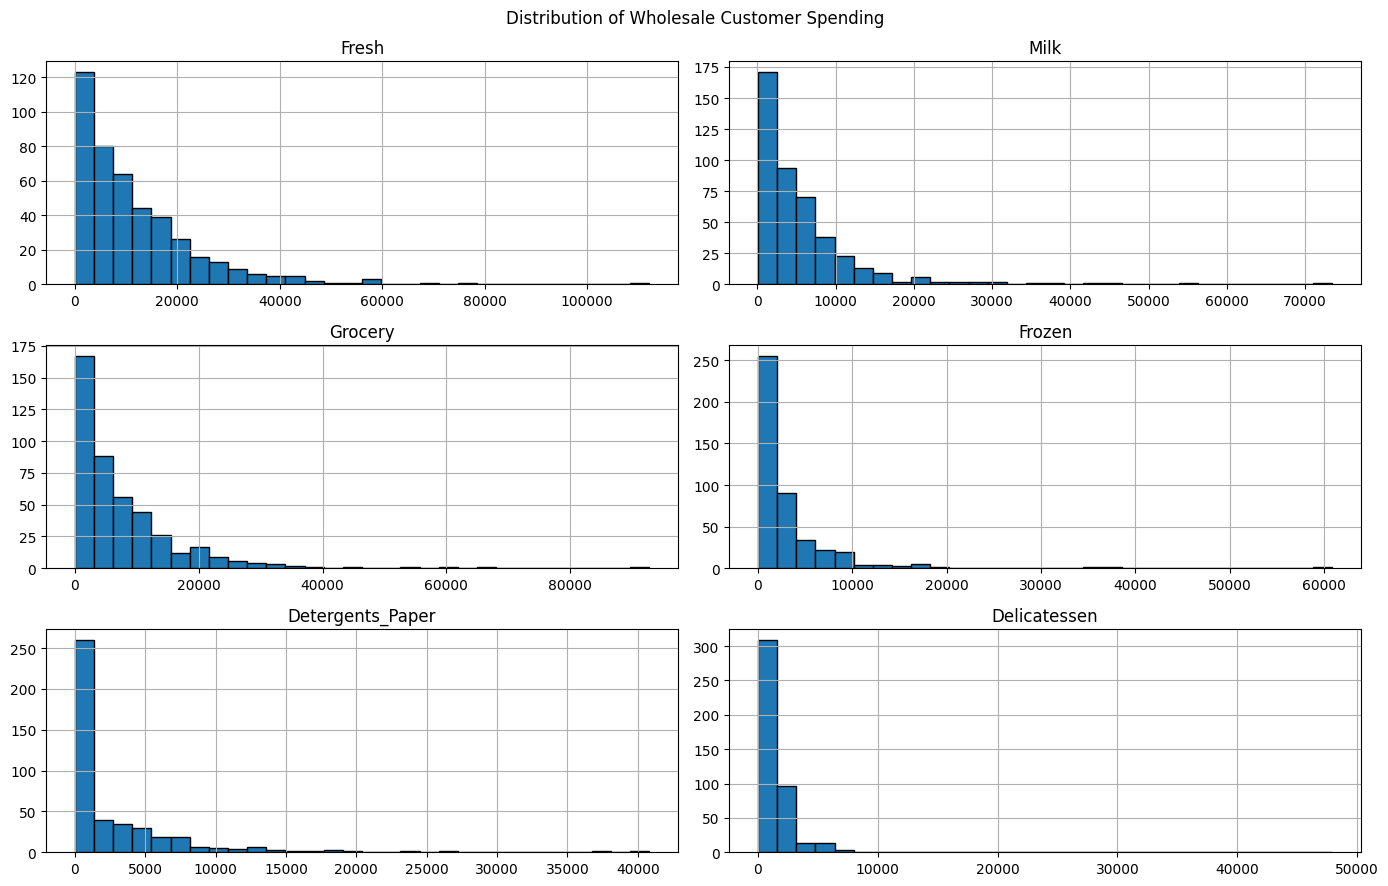

Fresh                2.561323
Milk                 4.053755
Grocery              3.587429
Frozen               5.907986
Detergents_Paper     3.631851
Delicatessen        11.151586
dtype: float64


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

#Ploting histograms for the six spending variables

wholesale_df[['Fresh', 'Milk', 'Grocery',
    'Frozen', 'Detergents_Paper',
    'Delicatessen']].hist(
        figsize=(14, 9),
        bins=30,
        edgecolor='black'
    )

plt.suptitle("Distribution of Wholesale Customer Spending")
plt.tight_layout()
plt.show()

spending_columns = [
    'Fresh', 'Milk', 'Grocery',
    'Frozen', 'Detergents_Paper',
    'Delicatessen'
]

print(wholesale_df[spending_columns].skew())

The data shows that the spending habits across the different products is skewed to the right,showing that most cuostomers have relatively lower spending values apart from the few that have higher spending values.All the 6 columns show that they are positively with spending on delicatessen having a higher skewness,which means that a small number of customers have exceptionally high spending as compared to the majority,and because this is a clustering problems,we cant assume that they are errors.

In [ ]:
#Data preparation
spending_columns = [
    'Fresh', 'Milk', 'Grocery',
    'Frozen', 'Detergents_Paper',
    'Delicatessen'
]

X = wholesale_df[spending_columns]

Since Channel and Region do not illustrate spending behaviour,they have to be excluded from the spending variables.

In [ ]:
import numpy as np
#Applying logarithmic transformation

X_log = np.log1p(X)

#Examining the transformed data
X_log.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
0,9.446992,9.175438,8.930891,5.370638,7.891705,7.199678
1,8.861917,9.191259,9.166284,7.474772,8.099858,7.482682
2,8.756840,9.083529,8.947026,7.785721,8.165364,8.967632
3,9.492960,7.087574,8.348064,8.764834,6.230481,7.489412
4,10.026413,8.596189,8.881697,8.272826,7.483244,8.553718


Since the data is highly skewed,we use the logarithmic transformation to reduce the effect of etreme values on the smaller values

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

#Initialising the standard scaler
scaler = StandardScaler()

#Fitting and transforming the data
X_scaled = scaler.fit_transform(X_log)

#Converting back into a DataFrame for easier inspection
X_scaled = pd.DataFrame(
    X_scaled,
    columns=spending_columns
)

X_scaled.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
0,0.486184,0.976299,0.440155,-1.509250,0.644143,0.408966
1,0.087889,0.990956,0.652171,0.134052,0.766043,0.627926
2,0.016356,0.891151,0.454687,0.376899,0.804405,1.776833
3,0.517477,-0.957973,-0.084792,1.141574,-0.328712,0.633133
4,0.880631,0.439662,0.395847,0.757322,0.404939,1.456588


The 2 columns for channel and Region are excluded from the dateset(since they
do not explain spending habits) and the data is logarithymically transformed, the variables were standardised so that variables can easily be compared and then fitted

In [ ]:
from sklearn.neighbors import NearestNeighbors

def hopkins_statistic(X, sample_size=None, random_state=42):

    np.random.seed(random_state)

    n, d = X.shape

    if sample_size is None:
        sample_size = int(0.1 * n)

    #Randomly selecting actual observations
    random_indices = np.random.choice(
        n, sample_size, replace=False
    )

    actual_sample = X[random_indices]

    #Generating artificial observations
    minimum = X.min(axis=0)
    maximum = X.max(axis=0)

    artificial_sample = np.random.uniform(
        minimum, maximum,
        size=(sample_size, d)
    )

    #Fitting nearest-neighbour model
    neighbours = NearestNeighbors(n_neighbors=2)
    neighbours.fit(X)

    #Distances for actual observations
    actual_distances = neighbours.kneighbors(
        actual_sample, n_neighbors=2
    )[0][:, 1]

    #Distances for artificial observations
    artificial_distances = neighbours.kneighbors(
        artificial_sample, n_neighbors=1
    )[0][:, 0]

    #Calculating Hopkins statistic
    H = artificial_distances.sum() / (
        artificial_distances.sum()
        + actual_distances.sum()
    )

    return H


#Calculating Hopkins statistic
H = hopkins_statistic(X_scaled.values)

print("Hopkins Statistic:", H)

Hopkins Statistic: 0.7529156617216883


Since the results are consistently above 0.5 using the hopkins    statistic,this illustrates that there is a tendency of clustering in the spending behaviour of the customers

In [ ]:
#question 2, Comparing the 3 clustering approaches
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

#using partitioning clustering algorithm: K means
kmeans_results = []

for k in range(2, 9):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_scaled)

    silhouette = silhouette_score(X_scaled, labels)

    db_index = davies_bouldin_score(
        X_scaled, labels
    )

    ch_index = calinski_harabasz_score(
        X_scaled, labels
    )

    kmeans_results.append({
        'Clusters': k,
        'Silhouette': silhouette,
        'Davies_Bouldin': db_index,
        'Calinski_Harabasz': ch_index
    })

kmeans_results = pd.DataFrame(kmeans_results)

print(kmeans_results)

   Clusters  Silhouette  Davies_Bouldin  Calinski_Harabasz
0         2    0.290328        1.351502         189.049797
1         3    0.258278        1.348236         152.837245
2         4    0.188495        1.540772         131.319856
3         5    0.191585        1.484279         118.000499
4         6    0.195319        1.413524         108.299957
5         7    0.195780        1.391898         103.208189
6         8    0.191491        1.385463          97.385586


The optimal number of clusters were evaluated using silhouette score,Davies-Bouldin index,and Calinski Harabasz index. The results suggest that k=2,k=3,as the better clusters,with the k=2 cluster being the best in 2 evaluation metrics,and k=3 being the best in 1 metric.I chose cluster k=3 so as to have a more detailed customer segmentation and more customer groups so as to have beetter targeted marketing strategies.

In [ ]:
#Implementing hierarchical clustering:
hierarchical_results = []

for linkage in ['ward', 'average', 'complete']:

    for k in range(2, 6):

        model = AgglomerativeClustering(
            n_clusters=k,
            linkage=linkage
        )

        labels = model.fit_predict(X_scaled)

        silhouette = silhouette_score(
            X_scaled, labels
        )

        db_index = davies_bouldin_score(
            X_scaled, labels
        )

        ch_index = calinski_harabasz_score(
            X_scaled, labels
        )

        hierarchical_results.append({
            'Linkage': linkage,
            'Clusters': k,
            'Silhouette': silhouette,
            'Davies_Bouldin': db_index,
            'Calinski_Harabasz': ch_index
        })

hierarchical_results = pd.DataFrame(
    hierarchical_results
)

print(hierarchical_results)

     Linkage  Clusters  Silhouette  Davies_Bouldin  Calinski_Harabasz
0       ward         2    0.258495        1.600363         134.624461
1       ward         3    0.254657        1.538995         116.799278
2       ward         4    0.202080        1.521091         108.606730
3       ward         5    0.202547        1.386198         100.014606
4    average         2    0.569055        0.882575          13.965034
5    average         3    0.541720        0.306636           9.055141
6    average         4    0.498035        0.329534           8.382897
7    average         5    0.383323        0.546727          11.897512
8   complete         2    0.322005        1.554272          61.991734
9   complete         3    0.298062        1.401550          37.844528
10  complete         4    0.259529        1.292025          38.944481
11  complete         5    0.227984        1.196766          34.793292


The average linkage appears to have the better results for 2 clusters and 3 clusters however when you investigate the number of entries in each cluster,its performed well because of the creation of very small clusters,therefore silhouette alone is not sufficient before understandig the number of entries in each cluster

In [ ]:
from sklearn.cluster import AgglomerativeClustering

#Performing clustering
model = AgglomerativeClustering(
    n_clusters=3,
    linkage='average'
)

#Assigning cluster labels
labels = model.fit_predict(X_scaled)

#Counting entries in each cluster
cluster_counts = pd.Series(labels).value_counts().sort_index()

print(cluster_counts)

0    438
1      1
2      1
Name: count, dtype: int64


In [ ]:
#Using density-based clustering :DBSCAN
dbscan_results = []

for eps in [0.5, 0.7, 0.9, 1.0, 1.1, 1.2]:

    for min_samples in [5, 8, 10]:

        model = DBSCAN(
            eps=eps,
            min_samples=min_samples
        )

        labels = model.fit_predict(X_scaled)

        # Identifying the number of clusters,
        # excluding noise labelled -1
        number_of_clusters = len(
            set(labels)
        ) - (1 if -1 in labels else 0)

        #Identifying noise observations
        noise_count = np.sum(labels == -1)

        # Calculating metrics only if at least
        # two valid clusters exist
        if number_of_clusters >= 2:

            mask = labels != -1

            silhouette = silhouette_score(
                X_scaled[mask],
                labels[mask]
            )

            db_index = davies_bouldin_score(
                X_scaled[mask],
                labels[mask]
            )

        else:
            silhouette = np.nan
            db_index = np.nan

        dbscan_results.append({
            'Epsilon': eps,
            'Min_Samples': min_samples,
            'Clusters': number_of_clusters,
            'Noise': noise_count,
            'Silhouette': silhouette,
            'Davies_Bouldin': db_index
        })

dbscan_results = pd.DataFrame(dbscan_results)

print(dbscan_results)

    Epsilon  Min_Samples  Clusters  Noise  Silhouette  Davies_Bouldin
0       0.5            5         1    435         NaN             NaN
1       0.5            8         0    440         NaN             NaN
2       0.5           10         0    440         NaN             NaN
3       0.7            5         4    343    0.364047        1.252340
4       0.7            8         3    397    0.553311        0.695310
5       0.7           10         1    422         NaN             NaN
6       0.9            5         3    160    0.274144        0.810152
7       0.9            8         1    211         NaN             NaN
8       0.9           10         2    248    0.461317        0.858211
9       1.0            5         1    124         NaN             NaN
10      1.0            8         2    146    0.245019        0.840130
11      1.0           10         1    170         NaN             NaN
12      1.1            5         1     96         NaN             NaN
13      1.1         

using the best candidate configurations with a high silhouette of 0.553311, DBSCAN classified 397 out of 440 customers as noise and this represents 90.2% of the dataset.even when the remaining customers form well separated groups,this configuration will be unsuitable as the primary customer segmentation model.DBSCAN is useful in identifying unusual customers but its assignment of many customers as noise limits its usage when performing segmentation tasks.

In [ ]:
#Assigning descriptive names to the resulting clusters
#Creating the final K-Means model
final_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

#Assigning customers to clusters
wholesale_df['Cluster'] = final_model.fit_predict(X_scaled)

#Displaying the number of customers in each cluster
print(wholesale_df['Cluster'].value_counts().sort_index())

Cluster
0    145
1    212
2     83
Name: count, dtype: int64


cluster 1 is the largest cluster with 212 entries and the least cluster with 83 entries

In [ ]:
#Calculating average spending for each cluster
cluster_profiles = wholesale_df.groupby('Cluster')[
    spending_columns
].mean()

print(cluster_profiles.round(2))

            Fresh      Milk   Grocery   Frozen  Detergents_Paper  Delicatessen
Cluster                                                                       
0        17182.39  10658.08  13380.98  4181.11           5003.64       2867.22
1        11992.59   1995.43   2496.92  3277.84            425.91        892.50
2         2966.93   7010.90  12397.28   608.28           5446.23        795.00
